In [1]:
import pandas as pd

In [2]:
from sklearn.preprocessing import StandardScaler

In [3]:
from sklearn.model_selection import train_test_split

In [4]:
import tensorflow as tf

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

Importamos el set de datos de el titanic

In [6]:
titanic = pd.read_csv("./train.csv")

In [7]:
# dataset.head(#) muestra las primeras 5 filas de datos de el set de datos

In [8]:
# del dataset["columna"] elimina una columna

In [9]:
# dataset.info muestra un resumen general de base de datos, como el tipo de dato y la cantidad de nulos

In [10]:
# dataset.describe

In [11]:
titanic.head(5)

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [12]:
titanic.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8492 non-null   str    
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   str    
 4   Destination   8511 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(2), str(5)
memory usage: 891.5+ KB


In [13]:
titanic.describe()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
count,8514.000000,8512.000000,8510.000000,8485.000000,8510.000000,8505.000000
mean,28.827930,224.687617,458.077203,173.729169,311.138778,304.854791
std,14.489021,666.717663,1611.489240,604.696458,1136.705535,1145.717189
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,19.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,38.000000,47.000000,76.000000,27.000000,59.000000,46.000000
max,79.000000,14327.000000,29813.000000,23492.000000,22408.000000,24133.000000


In [14]:
del titanic["PassengerId"]

In [15]:
del titanic["Name"]

In [16]:
titanic[["Deck","Num","Side"]] = titanic["Cabin"].str.split('/', expand=True)

In [17]:
del titanic["Cabin"]

In [18]:
titanic["Europa"] = titanic["HomePlanet"] == "Europa"
titanic["Earth"] = titanic["HomePlanet"] == "Earth"
titanic["Mars"] = titanic["HomePlanet"] == "Mars"

In [19]:
del titanic["HomePlanet"]

In [20]:
titanic["TRAPPIST-1e"] = titanic["Destination"] == "TRAPPIST-1e"
titanic["55-Cancri-e"] = titanic["Destination"] == "55 Cancri e"
titanic["PSO-J318.5-22"] = titanic["Destination"] == "PSO J318.5-22"

In [21]:
del titanic["Destination"]

In [22]:
titanic = pd.concat([titanic,pd.get_dummies(titanic["Deck"], prefix = "Deck")], axis = 1)

In [23]:
titanic = pd.concat([titanic,pd.get_dummies(titanic["Side"], prefix = "Side")], axis = 1)

In [24]:
del titanic["Deck"]

In [25]:
del titanic["Side"]

In [26]:
titanic.head()

,CryoSleep,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,Num,...,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T,Side_P,Side_S
0,False,39.0,False,0.0,0.0,0.0,0.0,0.0,False,0,...,False,True,False,False,False,False,False,False,True,False
1,False,24.0,False,109.0,9.0,25.0,549.0,44.0,True,0,...,False,False,False,False,False,True,False,False,False,True
2,False,58.0,True,43.0,3576.0,0.0,6715.0,49.0,False,0,...,True,False,False,False,False,False,False,False,False,True
3,False,33.0,False,0.0,1283.0,371.0,3329.0,193.0,False,0,...,True,False,False,False,False,False,False,False,False,True
4,False,16.0,False,303.0,70.0,151.0,565.0,2.0,True,1,...,False,False,False,False,False,True,False,False,False,True


In [27]:
#Eliminando nulos

In [28]:
titanicNull = titanic.copy()

In [29]:
titanic["CryoSleep"] = titanic["CryoSleep"].fillna(False)

In [30]:
age_mean = titanic["Age"].mean()
titanic["Age"] = titanic["Age"].fillna(age_mean)

In [31]:
titanic["VIP"] = titanic["VIP"].fillna(False)

In [32]:
titanic["RoomService"] = titanic["RoomService"].fillna(0)

In [33]:
foodCourt_mean = titanic["FoodCourt"].mean()
titanic["FoodCourt"] = titanic["FoodCourt"].fillna(foodCourt_mean)

In [34]:
mall_mean = titanic["ShoppingMall"].mean()
titanic["ShoppingMall"] = titanic["ShoppingMall"].fillna(mall_mean)

In [35]:
Spa_mean = titanic["Spa"].mean()
titanic["Spa"] = titanic["Spa"].fillna(Spa_mean)

In [36]:
vrDeck_mean = titanic["VRDeck"].mean()
titanic["VRDeck"] = titanic["VRDeck"].fillna(vrDeck_mean)

In [37]:
titanic["Num"] = titanic["Num"].fillna("0")

In [38]:
titanic["Num"] = titanic["Num"].astype("float64")

In [39]:
titanic["CryoSleep"] = titanic["CryoSleep"].astype("bool")

In [40]:
titanic["VIP"] = titanic["VIP"].astype("bool")

In [41]:
titanic.head()

,CryoSleep,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,Num,...,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T,Side_P,Side_S
0,False,39.0,False,0.0,0.0,0.0,0.0,0.0,False,0.0,...,False,True,False,False,False,False,False,False,True,False
1,False,24.0,False,109.0,9.0,25.0,549.0,44.0,True,0.0,...,False,False,False,False,False,True,False,False,False,True
2,False,58.0,True,43.0,3576.0,0.0,6715.0,49.0,False,0.0,...,True,False,False,False,False,False,False,False,False,True
3,False,33.0,False,0.0,1283.0,371.0,3329.0,193.0,False,0.0,...,True,False,False,False,False,False,False,False,False,True
4,False,16.0,False,303.0,70.0,151.0,565.0,2.0,True,1.0,...,False,False,False,False,False,True,False,False,False,True


In [42]:
titanic.describe()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Num
count,8693.000000,8693.000000,8693.000000,8693.000000,8693.000000,8693.000000,8693.000000
mean,28.827930,220.009318,458.077203,173.729169,311.138778,304.854791,586.624065
std,14.339054,660.519050,1594.434978,597.417440,1124.675871,1133.259049,513.880084
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,20.000000,0.000000,0.000000,0.000000,0.000000,0.000000,152.000000
50%,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,407.000000
75%,37.000000,41.000000,118.000000,45.000000,89.000000,71.000000,983.000000
max,79.000000,14327.000000,29813.000000,23492.000000,22408.000000,24133.000000,1894.000000


In [43]:
age_columns = list(range(101))

age_dummies = pd.get_dummies(
    titanic["Age"].round().clip(0, 100).astype(int),
    prefix="Age"
)

age_dummies = age_dummies.reindex(
    columns=[f"Age_{i}" for i in age_columns],
    fill_value=0
)

titanic = pd.concat([titanic, age_dummies], axis=1)

In [44]:
X_train = titanic.drop("Transported", axis = 1)
y_train = titanic["Transported"]

In [45]:
#Agregando el set de datos para test

In [46]:
titanic_test = pd.read_csv("./test.csv")

In [47]:
del titanic_test["PassengerId"]
del titanic_test["Name"]

titanic_test[["Deck","Num","Side"]] = titanic_test["Cabin"].str.split('/', expand=True)
del titanic_test["Cabin"]

titanic_test["Europa"] = titanic_test["HomePlanet"] == "Europa"
titanic_test["Earth"] = titanic_test["HomePlanet"] == "Earth"
titanic_test["Mars"] = titanic_test["HomePlanet"] == "Mars"
del titanic_test["HomePlanet"]

titanic_test["TRAPPIST-1e"] = titanic_test["Destination"] == "TRAPPIST-1e"
titanic_test["55-Cancri-e"] = titanic_test["Destination"] == "55 Cancri e"
titanic_test["PSO-J318.5-22"] = titanic_test["Destination"] == "PSO J318.5-22"
del titanic_test["Destination"]

titanic_test = pd.concat([titanic_test,pd.get_dummies(titanic_test["Deck"], prefix = "Deck")], axis = 1)
del titanic_test["Deck"]

titanic_test = pd.concat([titanic_test,pd.get_dummies(titanic_test["Side"], prefix = "Side")], axis = 1)
del titanic_test["Side"]

In [48]:
titanic_testNull = titanic_test.copy()

In [49]:
titanic_test["CryoSleep"] = titanic_test["CryoSleep"].fillna(False)

age_mean = titanic_test["Age"].mean()
titanic_test["Age"] = titanic_test["Age"].fillna(age_mean)

titanic_test["VIP"] = titanic_test["VIP"].fillna(False)

titanic_test["RoomService"] = titanic_test["RoomService"].fillna(0)

foodCourt_mean = titanic_test["FoodCourt"].mean()
titanic_test["FoodCourt"] = titanic_test["FoodCourt"].fillna(foodCourt_mean)

mall_mean = titanic_test["ShoppingMall"].mean()
titanic_test["ShoppingMall"] = titanic_test["ShoppingMall"].fillna(mall_mean)

Spa_mean = titanic_test["Spa"].mean()
titanic_test["Spa"] = titanic_test["Spa"].fillna(Spa_mean)

vrDeck_mean = titanic_test["VRDeck"].mean()
titanic_test["VRDeck"] = titanic_test["VRDeck"].fillna(vrDeck_mean)

titanic_test["Num"] = titanic_test["Num"].fillna("0")

titanic_test["Num"] = titanic_test["Num"].astype("float64")
titanic_test["CryoSleep"] = titanic_test["CryoSleep"].astype("bool")
titanic_test["VIP"] = titanic_test["VIP"].astype("bool")

In [50]:
age_dummies_test = pd.get_dummies(
    titanic_test["Age"].round().clip(0, 100).astype(int),
    prefix="Age"
)

age_dummies_test = age_dummies_test.reindex(
    columns=[f"Age_{i}" for i in range(101)],
    fill_value=0
)

titanic_test = pd.concat([titanic_test, age_dummies_test], axis=1)

In [51]:
X_test = titanic_test

titanic_y_test = pd.read_csv("./result.csv")
y_test = titanic_y_test["Transported"]

In [52]:
#X_train, X_test, y_train, y_test = train_test_split(
#    X, y, test_size=0.30, random_state=42, stratify = y
#)

In [53]:
X_test.isnull().sum()

CryoSleep      0
Age            0
VIP            0
RoomService    0
FoodCourt      0
              ..
Age_96         0
Age_97         0
Age_98         0
Age_99         0
Age_100        0
Length: 126, dtype: int64

In [54]:
X_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Columns: 126 entries, CryoSleep to Age_100
dtypes: bool(98), float64(7), int64(21)
memory usage: 2.7 MB


In [55]:
#normalizamos

In [56]:
numeric_val = X_train[["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck","Num"]]
scaler = StandardScaler()
scaler.fit(numeric_val)

StandardScaler()

In [57]:
X_train[["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck","Num"]] = scaler.transform(numeric_val)

In [58]:
X_test[["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck","Num"]] = scaler.transform(X_test[[ "RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck","Num"]])

In [59]:
X_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 4277 entries, 0 to 4276
Columns: 126 entries, CryoSleep to Age_100
dtypes: bool(97), float64(7), int64(22)
memory usage: 1.3 MB


In [60]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),

    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.2),

    tf.keras.layers.Dense(32, activation="relu"),
    
    tf.keras.layers.Dense(units = 1, activation = "sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[tf.keras.metrics.F1Score(threshold=0.5)]
)

In [61]:
model.fit(X_train, y_train, epochs = 200)#epochs = 500 alcanza un 92 de presicion, 200 = 89-90

Epoch 1/200
272/272 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - f1_score: 0.6759 - loss: 0.6219  
Epoch 2/200
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 982us/step - f1_score: 0.7778 - loss: 0.4632
Epoch 3/200
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - f1_score: 0.7918 - loss: 0.4374  
Epoch 4/200
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 974us/step - f1_score: 0.7966 - loss: 0.4276
Epoch 5/200
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 981us/step - f1_score: 0.8005 - loss: 0.4211
Epoch 6/200
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - f1_score: 0.7996 - loss: 0.4173  
Epoch 7/200
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 996us/step - f1_score: 0.8012 - loss: 0.4107
Epoch 8/200
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 967us/step - f1_score: 0.8013 - loss: 0.4075
Epoch 9/200
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 970us/step - f1_score: 0.8056 - loss: 0.4031
Epoch 10/200
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 969us/step - f1_score: 0.8079 - loss: 0.4012
Epoch 11/200
272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 970us/step - f1_score: 0.8105 - loss: 0.3999
Epoch 12/200
272/27

In [62]:
y_predict = model.predict(X_test) > 0.5

134/134 ━━━━━━━━━━━━━━━━━━━━ 0s 759us/step


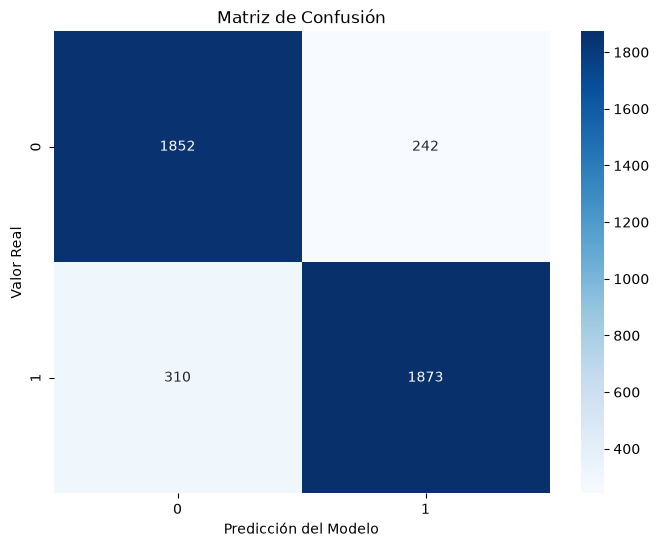

In [63]:
matriz_confusion = tf.math.confusion_matrix(labels=y_test, predictions=y_predict)
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_confusion, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusión')
plt.show()
     

In [64]:
titanicNull = titanicNull.dropna(axis=0)

In [65]:
titanicNull["Num"] = titanicNull["Num"].astype("float64")
titanicNull["CryoSleep"] = titanicNull["CryoSleep"].astype("bool")
titanicNull["VIP"] = titanicNull["VIP"].astype("bool")

In [66]:
titanicNull.info()

<class 'pandas.DataFrame'>
Index: 7084 entries, 0 to 8692
Data columns (total 26 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   CryoSleep      7084 non-null   bool   
 1   Age            7084 non-null   float64
 2   VIP            7084 non-null   bool   
 3   RoomService    7084 non-null   float64
 4   FoodCourt      7084 non-null   float64
 5   ShoppingMall   7084 non-null   float64
 6   Spa            7084 non-null   float64
 7   VRDeck         7084 non-null   float64
 8   Transported    7084 non-null   bool   
 9   Num            7084 non-null   float64
 10  Europa         7084 non-null   bool   
 11  Earth          7084 non-null   bool   
 12  Mars           7084 non-null   bool   
 13  TRAPPIST-1e    7084 non-null   bool   
 14  55-Cancri-e    7084 non-null   bool   
 15  PSO-J318.5-22  7084 non-null   bool   
 16  Deck_A         7084 non-null   bool   
 17  Deck_B         7084 non-null   bool   
 18  Deck_C         7084 non-

In [67]:
age_columns = list(range(101))

age_dummies = pd.get_dummies(
    titanicNull["Age"].round().clip(0, 100).astype(int),
    prefix="Age"
)

age_dummies = age_dummies.reindex(
    columns=[f"Age_{i}" for i in age_columns],
    fill_value=0
)

titanicNull = pd.concat([titanicNull, age_dummies], axis=1)

In [68]:
X_trainNull = titanicNull.drop("Transported", axis = 1)
y_trainNull = titanicNull["Transported"]

In [69]:
numeric_valNull = X_trainNull[["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck","Num"]]
scalerNull = StandardScaler()
scalerNull.fit(numeric_valNull)

StandardScaler()

In [70]:
X_trainNull[["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck","Num"]] = scalerNull.transform(numeric_valNull)

In [71]:
X_test[["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck","Num"]] = scalerNull.transform(X_test[[ "RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck","Num"]])

In [72]:
modelNull = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_trainNull.shape[1],)),

    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.2),

    tf.keras.layers.Dense(32, activation="relu"),
    
    tf.keras.layers.Dense(units = 1, activation = "sigmoid")
])

modelNull.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[tf.keras.metrics.F1Score(threshold=0.5)]
)

In [ ]:
modelNull.fit(X_trainNull, y_trainNull, epochs = 200)#epochs = 500 alcanza un 92 de presicion, 200 = 90-91

Epoch 1/200
222/222 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - f1_score: 0.6222 - loss: 0.7045  
Epoch 2/200
222/222 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - f1_score: 0.7634 - loss: 0.4919  
Epoch 3/200
222/222 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - f1_score: 0.7897 - loss: 0.4475  
Epoch 4/200
222/222 ━━━━━━━━━━━━━━━━━━━━ 0s 995us/step - f1_score: 0.7966 - loss: 0.4326
Epoch 5/200
222/222 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - f1_score: 0.8028 - loss: 0.4210  
Epoch 6/200
222/222 ━━━━━━━━━━━━━━━━━━━━ 0s 976us/step - f1_score: 0.8019 - loss: 0.4189
Epoch 7/200
222/222 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - f1_score: 0.8053 - loss: 0.4110  
Epoch 8/200
222/222 ━━━━━━━━━━━━━━━━━━━━ 0s 955us/step - f1_score: 0.8040 - loss: 0.4025
Epoch 9/200
222/222 ━━━━━━━━━━━━━━━━━━━━ 0s 981us/step - f1_score: 0.8111 - loss: 0.4012
Epoch 10/200
222/222 ━━━━━━━━━━━━━━━━━━━━ 0s 986us/step - f1_score: 0.8124 - loss: 0.3962
Epoch 11/200
222/222 ━━━━━━━━━━━━━━━━━━━━ 0s 980us/step - f1_score: 0.8121 - loss: 0.3929
Epoch 12/200
222/22

In [ ]:
X_trainNull.info()

In [ ]:
y_predictNull = modelNull.predict(X_test) > 0.5

In [ ]:
matriz_confusion = tf.math.confusion_matrix(labels=y_test, predictions=y_predictNull)
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_confusion, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusión')
plt.show()